# Ghost of the Machine
Problem from IOAI 2026 (Individual Contest, task 5)

> 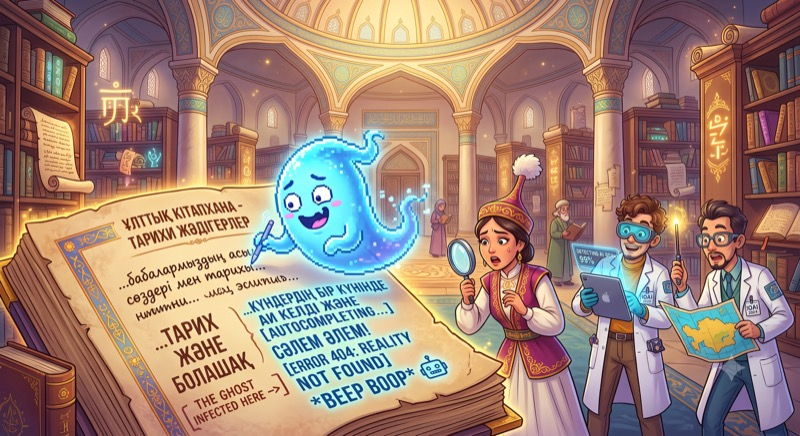
>
> Strange things are happening at the National Archive of Kazakhstan. Librarians say that some books used to end differently, but no one can prove it: every copy is the same, and every story still makes sense. You are invited as an AI researcher to locate the changes.

## Task description

A passage begins as human-written text and, at some point, silently switches to a continuation generated by a language model. Read as a whole, it looks like one coherent piece, but somewhere in the middle the author changes from a person to a machine. **Find that switch: the character index where the human part ends and the machine part begins.**

Each sample is a single string `text` with exactly one boundary. Everything before it is human; everything from it onward is machine-generated.

- **Part A** (before the boundary): an excerpt of human-written text.
- **Part B** (from the boundary on): a continuation produced by a language model, conditioned on Part A.
- Each side has at least 180 words; the whole passage has about 500 to 800 words.
- `boundary_char_index` is the character offset where Part A ends: `text[:boundary_char_index]` is the human part and `text[boundary_char_index:].lstrip()` is the machine part.

## Input

| Folder | Samples | Contest role |
|--------|---------|--------------|
| `data/train/` | 1,221 | labelled training set |
| `data/test/` | 380 | leaderboard A (live leaderboard during the contest) |
| `data/test_hidden/` | 380 | leaderboard B (final ranking), used only in the last cell |

Each folder has `data.jsonl` (`{'id': '...', 'text': '...'}` per line) and `answers.jsonl` (`{'id': '...', 'boundary_char_index': 1842}` per line). Contestants only had the train answers; the test answers are here so you can score yourself. All three splits come from the same distribution.

Data from the [official Hugging Face dataset](https://huggingface.co/datasets/IOAI-official/ioai-2026-ghost-of-the-machine).

## Constraints

- One GPU (about 16 GB VRAM), no internet.
- **10 minutes** of wall-clock time for the whole run, including any training or fine-tuning plus inference.
- The only pretrained weights allowed are **[bge-base-en-v1.5](https://huggingface.co/BAAI/bge-base-en-v1.5)**, a 110M-parameter text encoder (embedding model, not a generative LM). You may use it frozen or fine-tune it on `train`.
- Classical tools are unrestricted: any scikit-learn style model on top of features you compute yourself is fine.

## Evaluation

For each sample, with prediction $p$ and true boundary $t$:

$$\text{score} = \exp\left(-\frac{|p - t|}{\tau}\right), \quad \tau = 100$$

<table align='center' style='text-align: center'>
  <tr><th>Distance (characters)</th><th>Score</th></tr>
  <tr><td>0</td><td>1.00</td></tr>
  <tr><td>25</td><td>0.78</td></tr>
  <tr><td>50</td><td>0.61</td></tr>
  <tr><td>100</td><td>0.37</td></tr>
  <tr><td>500</td><td>0.01</td></tr>
</table>

The final score is the mean over all samples, on a 0 to 100 scale. A missing id, a non-integer value or an index outside `[0, len(text)]` scores 0 for that sample.

On leaderboard A, the baseline scored `28.6` and the Scientific Committee scored `93.41` by fine-tuning the encoder and locating the switch as a changepoint over sentences.

## Submission

A single notebook named `solution.ipynb`. It reads the test passages and writes `answers.jsonl`, one line per sample:

```json
{'id': 'example_000123', 'boundary_char_index': 1790}
{'id': 'example_000124', 'boundary_char_index': 2450}
```

Every test id must appear exactly once. During grading the test folder was swapped for the hidden set without answers, and the notebook was run again.

### Loading the data

In [68]:
import json
import math
import re
import pandas as pd

DATA = 'data'


def read_jsonl(path):
    with open(path, encoding='utf-8') as file:
        return [json.loads(line) for line in file if line.strip()]


def load_split(name):
    rows = read_jsonl(f'{DATA}/{name}/data.jsonl')
    answers = {r['id']: r['boundary_char_index'] for r in read_jsonl(f'{DATA}/{name}/answers.jsonl')}
    return rows, answers


train_rows, train_answers = load_split('train')
test_rows, test_answers = load_split('test')
print(f'train: {len(train_rows)} passages, test: {len(test_rows)} passages')

train: 1221 passages, test: 380 passages


Let's look at one passage, marking where the machine takes over.

In [69]:
sample = train_rows[0]
boundary = train_answers[sample['id']]
print(sample['text'][:boundary])
print('\n' + '=' * 30 + ' machine starts here ' + '=' * 30 + '\n')
print(sample['text'][boundary:])

Tello bequeathed his extensive landed and movable wealth, which was concentrated in the lower Surselva between Flims and Trun, to the Abbey. Cadi, the Sursilvan for "House of God" (Casa Dei), is the historical name of Disentis Abbey and its feudal territories. Charlemagne visited the re-built abbey on his return journey from Rome in 800 and made many benefactions to it. It was a "Reichskloster" (directly answerable to the Emperor and thus free from the claims of other territorial lords) from very early in its existence. Disentis' claim to imperial interest was its strategic position on the Lukmanier Pass, which the Emperors Otto I and Frederick Barbarossa crossed during their journeys south. Successive abbots were able to capitalise on this to the advantage of the abbey, which received landholdings that extended as far as Lombardy, and which resulted in the establishment of a monastic state of considerable size. Udalric I (1031–55) was the first abbot to be made a prince of the empire,

Now, we may also look at the very last character before transition. Let's see how that looks for a few samples.

In [70]:
for i in range(10):
    sample = train_rows[i]
    boundary = train_answers[sample['id']]
    print(sample['text'][boundary - 2:boundary - 1])

.
!
.
.
.
.
.
.
.
.


It looks like the transition always comes in a punctuation. This narrows down our search quite a lot.

Let's now create DataFrames so that we have more control over our data.

In [76]:
test_answers_df = pd.Series(test_answers, name='boundary_char_index').rename_axis('id').reset_index()
test_df = pd.DataFrame(test_rows).merge(test_answers_df, on='id')


train_answers_df = pd.Series(train_answers, name='boundary_char_index').rename_axis('id').reset_index()
train_df = pd.DataFrame(train_rows).merge(train_answers_df, on='id')

train_df

,id,text,boundary_char_index
0,example_000000,Tello bequeathed his extensive landed and mova...,2466
1,example_000001,Judge joins the movement but is soon beset by ...,3036
2,example_000002,It is the third largest city of Bastar divisio...,2198
3,example_000003,The pair are also credited with writing and pe...,1921
4,example_000004,"Life He was born at Harrow on the Hill, to the...",2473
...,...,...,...
1216,example_001223,Mizdirection later that year would return to S...,1569
1217,example_001224,"Also in the cast are Lee Grant, Diana Sands, P...",2644
1218,example_001225,Some of the most important chiefs of Western N...,2549
1219,example_001226,The state of New York assumed maintenance of t...,2571


Now, let's modify this a bit. We wanna classify whether something is or isn't AI: binary classification. Since we know those spots are split by punctuation, we can do just that, and create a huge dataset for the classification.

In [77]:
def split_sentences(text, boundary):
    starts = [0] + [m.end() for m in re.finditer(r'[.!?]\s+', text)]
    ends = starts[1:] + [len(text)]
    return [(text[s:e].strip(), int(s >= boundary)) for s, e in zip(starts, ends)]


train_sentences_df = pd.DataFrame(
    [(row.id, sent, label)
     for row in train_df.itertuples()
     for sent, label in split_sentences(row.text, row.boundary_char_index)],
    columns=['id', 'sentence', 'is_ai'],
)

test_sentences_df = pd.DataFrame(
    [(row.id, sent, label)
     for row in test_df.itertuples()
     for sent, label in split_sentences(row.text, row.boundary_char_index)],
    columns=['id', 'sentence', 'is_ai'],
)

train_sentences_df[train_sentences_df['id'] == 'example_000000']

,id,sentence,is_ai
0,example_000000,Tello bequeathed his extensive landed and mova...,0
1,example_000000,"Cadi, the Sursilvan for ""House of God"" (Casa D...",0
2,example_000000,Charlemagne visited the re-built abbey on his ...,0
3,example_000000,"It was a ""Reichskloster"" (directly answerable ...",0
4,example_000000,Disentis' claim to imperial interest was its s...,0
5,example_000000,Successive abbots were able to capitalise on t...,0
6,example_000000,Udalric I (1031–55) was the first abbot to be ...,0
7,example_000000,The subjects of Disentis Abbey first used thei...,0
8,example_000000,They had their own Landammann (mistral) from 1...,0
9,example_000000,Cadi became an autonomous commune (cumin grond...,0


### Loading the encoder
The only pretrained model allowed is `bge-base-en-v1.5`, a text encoder. We use it frozen, through `sentence_transformers`. It turns each sentence into an embedding we can feed to a classifier.

In [ ]:
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer("BAAI/bge-base-en-v1.5")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 20244.65it/s]


### Sentence embeddings
Now we encode every sentence of train and test. That's almost 33,000 training sentences, each one a vector of 768 numbers.

In [ ]:
train_embeddings = encoder.encode(list(train_sentences_df['sentence']))
test_embeddings = encoder.encode(list(test_sentences_df['sentence']))

train_embeddings.shape

(32913, 768)

Let's reduce the embeddings to 2 dimensions with PCA and plot them, colored by label, to see if human and AI sentences separate at all.

In [83]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

reduced_embeddings = pca.fit_transform(train_embeddings)

<Axes: >

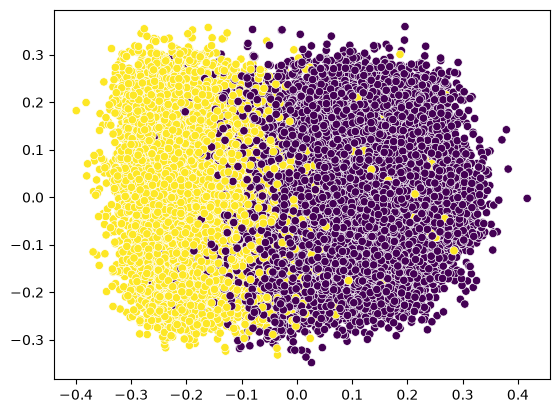

In [84]:
import seaborn as sns

sns.scatterplot(x=reduced_embeddings[:,0], y=reduced_embeddings[:,1], c=train_sentences_df['is_ai'])

Great, there's a clear pattern. AI sentences (yellow) sit on the left and human sentences (purple) on the right, with some overlap in the middle. Even a linear projection mostly separates them, so a classifier on top of the embeddings should do well.

### Training the classifier
I chose the **MLPClassifier** (a Neural Network) here, but any classifier with `predict_proba` would work. It learns to tell whether a single sentence is AI or not.

In [85]:
from sklearn.neural_network import MLPClassifier

model = MLPClassifier(max_iter=1000)

model.fit(train_embeddings, train_sentences_df['is_ai'])

,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",None


And we check the accuracy on the test sentences.

In [88]:
from sklearn.metrics import accuracy_score

test_preds = model.predict(test_embeddings)

accuracy_score(test_sentences_df['is_ai'], test_preds)

0.9607244807559799

About **96%** of the sentences are classified correctly. That's per sentence, though: the contest scores the boundary position, so we still need to turn these predictions into a single split per passage.

### Scoring
The contest metric: mean of $\exp(-|p - t| / 100)$, on a 0 to 100 scale.

In [89]:
def score(predictions, answers):
    return 100 * sum(math.exp(-abs(predictions.get(i, -10**9) - t) / 100) for i, t in answers.items()) / len(answers)

### Finding the boundary
Now we put it all together. The classifier gives each sentence a probability of being AI, and we know there's exactly one switch: everything before it is human and everything after it is AI.

So for each passage, we try every sentence as the split point. Sentences before the split should have a low $P(\text{AI})$ and the ones after it a high one, so each split gets the score

$$\sum_{\text{before}} \log(1 - p) + \sum_{\text{after}} \log p$$

and we keep the best one. The statement also says each side has at least 180 words, so we only allow splits that respect that. The predicted boundary is the character where the chosen sentence starts.

In [ ]:
import numpy as np

MIN_WORDS = 180  # each side (human / AI) has at least this many words

def best_split(p, words):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    human = np.concatenate([[0], np.cumsum(np.log(1 - p))])
    ai = np.concatenate([np.cumsum(np.log(p)[::-1])[::-1], [0]])
    scores = human + ai

    words_before = np.concatenate([[0], np.cumsum(words)])
    valid = (words_before >= MIN_WORDS) & (words_before[-1] - words_before >= MIN_WORDS)
    if valid.any():
        scores[~valid] = -np.inf
    return min(scores.argmax(), len(p) - 1)


def predict(rows, embeddings=None):
    starts = [[0] + [m.end() for m in re.finditer(r'[.!?]\s+', r['text'])] for r in rows]
    sentences = [[s for s, _ in split_sentences(r['text'], 0)] for r in rows]
    if embeddings is None:  # only for splits we haven't encoded yet (e.g. hidden)
        embeddings = SentenceTransformer("BAAI/bge-base-en-v1.5").encode([s for row in sentences for s in row])

    probs = model.predict_proba(embeddings)[:, 1]  # P(AI) per sentence
    predictions, i = {}, 0
    for r, st, sents in zip(rows, starts, sentences):
        words = [len(s.split()) for s in sents]
        k = best_split(probs[i:i + len(st)], words)
        i += len(st)
        predictions[r['id']] = st[k]
    assert i == len(probs)
    return predictions


test_predictions = predict(test_rows, test_embeddings)
print(f'test score: {score(test_predictions, test_answers):.2f}')

test score: 92.02


We got **92.02** on the test set (leaderboard A), way above the baseline's 28.6 and close to the Scientific Committee's 93.41. Worth reminding, though, we're not fine-tuning anything, and only using Scikit Learn, which is a huge win!

### A simpler alternative
The changepoint search works really well, but it's not the first thing you'd come up with during a contest, and it takes a while to get right. There's a much easier option that also does pretty well; call a sentence AI when its probability is above some threshold, and put the boundary at the first sentence that starts a streak of AI sentences in a row.

We need a streak, and not just the first AI sentence, because a single misclassified human sentence early in the passage would ruin the prediction (something like `[0, 0, 1, 0, 0, 0, 1, 1, 1, 1]`). We also know the human part has at least 180 words, so we only start looking for the streak after that. There are only two numbers to tune, the threshold and the streak length, so we can just try a grid of them.

In [ ]:
test_probs = model.predict_proba(test_embeddings)[:, 1]

def first_streak(p, words, threshold, run):
    is_ai = p > threshold
    start = np.searchsorted(np.cumsum(words), MIN_WORDS) + 1
    for k in range(start, len(p) - run + 1):
        if is_ai[k:k + run].all():
            return k
    return p.argmax()

def predict_streak(rows, probs, threshold, run):
    predictions, i = {}, 0
    for r in rows:
        starts = [0] + [m.end() for m in re.finditer(r'[.!?]\s+', r['text'])]
        words = [len(s.split()) for s, _ in split_sentences(r['text'], 0)]
        k = first_streak(probs[i:i + len(starts)], words, threshold, run)
        i += len(starts)
        predictions[r['id']] = starts[k]
    return predictions

results = pd.DataFrame(
    [(threshold, run, score(predict_streak(test_rows, test_probs, threshold, run), test_answers))
     for threshold in np.arange(0.05, 1, 0.05)
     for run in range(1, 7)],
    columns=['threshold', 'run', 'score'],
)
results.sort_values('score', ascending=False).head()

The best combination gets about **88.5** on the test set, with a low threshold (around 0.1) and 2 sentences in a row. On the hidden set the same parameters get about 85.5. That's a few points below the changepoint search, but it's way easier to write and to reason about.

Notice that `run=1`, taking just the first AI sentence, does worse (about 81 at best): one false positive is enough to throw the boundary off, which is exactly why we look for a streak. Skipping the first 180 words helps for the same reason, since it removes the false positives that would land too early.

### Submission
Write `answers.jsonl` in the contest format.

In [107]:
with open('answers.jsonl', 'w', encoding='utf-8') as file:
    for r in test_rows:
        file.write(json.dumps({'id': r['id'], 'boundary_char_index': test_predictions[r['id']]}) + '\n')

### Bonus: score on the hidden set
This wasn't visible during the contest: we run the same method on leaderboard B (`data/test_hidden/`), the split used for the final ranking.

In [108]:
hidden_rows, hidden_answers = load_split('test_hidden')
print(f'hidden score: {score(predict(hidden_rows), hidden_answers):.2f}')

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7391.40it/s]


hidden score: 92.20


**92.20** on the hidden set, so the method holds up on the split used for the final ranking.